# DDM-HMM states × trial modes

How do the collaborator's DDM-HMM states (K = 4, characterised in `2_ddm_hmm_states.ipynb`) map onto the 14 trial modes of `1_trial_modes.ipynb`?

- **Trial modes**: each trial's left paw + wheel syllables over four epochs (Pre-quiescence, Quiescence, Choice = go cue → feedback, ITI = feedback → trial end), each time-normalised to 10 bins, clustered by UMAP and watershed. A mode therefore describes the *shape* of the trial's behaviour, not its duration. But a long Choice epoch is mostly stillness, so RT gets in anyway.
- **DDM-HMM states**: these are per-mouse fits, so the states are compared across mice through the provisional names from step 2 (`Functions/ddm_hmm.py`, `name_state`). Only go trials in DDM states are used, since the omission state is the no-go trials.
- **Join**: the states files' `trial_id` equals the h5 `trial` column. This was verified on outcome and contrast in step 2. ZFM-06271 (1 session) is dropped.

The DDM state on a trial is inferred partly from that trial's own choice and RT, and the modes carry RT too. So some association is guaranteed. The question is how much of the mapping survives once RT and the other task variables are held fixed.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'ddm_hmm.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'paper-individuality'))
from Functions import ddm_hmm as dh
from Functions import trial_modes as tm
import paper_style as ps
ps.use('paper')

DATA = REPO / 'paper-individuality' / 'data' / 'neuromodulators'
RUN = 'left_paw_wheel_k8_own_lick-100ms'
MODES_FILE = DATA / f'trial_modes_{RUN}' / 'trials.pqt'   # the 14-mode fit
CACHE = DATA / 'ddm_hmm'
CACHE.mkdir(exist_ok=True)
K = 4
EXCLUDE = ['ZFM-06271']   # one session

trials, params = dh.load_all(K)
labels = dh.state_labels(trials, params)
modes = pd.read_parquet(MODES_FILE)

d = dh.go_trials(trials)
d = d[~d['subject'].isin(EXCLUDE)]
d = d.merge(modes[['session', 'trial_id', 'trial_cluster', *tm.EPOCHS]],
            left_on=['eid', 'trial'], right_on=['session', 'trial_id'], how='left')
d = d.merge(labels[['subject', 'state', 'label', 'tag']], on=['subject', 'state'])

cov = d.groupby('subject').agg(fitted_go_trials=('trial', 'size'),
                               in_mode_table=('trial_id', lambda x: x.notna().mean()),
                               mode_assigned=('trial_cluster', lambda x: x.notna().mean()))
display(cov.round(3))
print('fraction of trials with a mode, by state kind:')
print(d.groupby('label')['trial_cluster'].apply(lambda x: x.notna().mean()).round(3).to_dict())

j = d.dropna(subset=['trial_cluster']).copy()
j['mode'] = j['trial_cluster'].astype(int)
MICE = sorted(j['subject'].unique())
MODE_ORDER = [int(m) for m in tm.umap_order(modes)]           # colour-wheel order, as in 1_trial_modes
print(f"{len(j):,} trials with both a DDM state and a trial mode, {len(MICE)} mice")

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


,fitted_go_trials,in_mode_table,mode_assigned
subject,,,
ZFM-04019,14384,0.996,0.886
ZFM-08776,22910,0.996,0.535
ZFM-08818,18745,0.995,0.795
ZFM-08871,29119,0.997,0.940
ZFM-09365,30203,0.996,0.947
ZFM-09394,39125,0.996,0.956
ZFM-09439,35737,0.996,0.901


fraction of trials with a mode, by state kind:
{'biased-L': 0.949, 'biased-R': 0.94, 'disengaged': 0.835, 'engaged': 0.844, 'impulsive': 0.867, 'slow': 0.858}
165,477 trials with both a DDM state and a trial mode, 7 mice


Modes are missing for two reasons:
- a few trials have an incomplete epoch, so they are not in the mode table;
- about 13% of trials fall on the KDE background.

Whether a trial gets a mode does depend a little on the state, as the line above shows. The analysis uses only trials that have a mode.

## What each mode is

Each row of the table below describes one mode. The behaviour columns are per epoch:
- mean paw vigor (paw states are vigor-numbered, 0 = stillest of 8);
- P(whisking);
- P(licking).

They are followed by the mode's accuracy and median RT on these trials. Rows are in the colour-wheel order of `1_trial_modes`.

In [2]:
rows = []
for c in MODE_ORDER:
    paw, whisk, lick = tm.mode_fingerprint(modes.dropna(subset=['trial_cluster']), float(c))
    vigor = (np.arange(paw.shape[0])[:, None] * paw).sum(0)
    r = {'mode': c}
    for i, ep in enumerate(tm.EPOCHS):
        sl = slice(10 * i, 10 * i + 10)
        r[(ep, 'vigor')] = vigor[sl].mean(); r[(ep, 'whisk')] = whisk[sl].mean(); r[(ep, 'lick')] = lick[sl].mean()
    rows.append(r)
desc = pd.DataFrame(rows).set_index('mode')
desc.columns = pd.MultiIndex.from_tuples(desc.columns)
task = j.groupby('mode').agg(n=('trial', 'size'), acc=('correct', 'mean'), rt_median=('rt', 'median'))
task.columns = pd.MultiIndex.from_product([['task'], task.columns])
desc = desc.join(task)
SLOW_MODES = task.index[task[('task', 'rt_median')] > 1.5].tolist()
print('modes whose median RT is > 1.5 s:', SLOW_MODES)
(desc.style.format(precision=2).format({('task', 'n'): '{:,.0f}'})
 .background_gradient(subset=[c for c in desc.columns if c[1] == 'vigor'], cmap='Purples', vmin=0, vmax=4.5)
 .background_gradient(subset=[c for c in desc.columns if c[1] in ('whisk', 'lick')], cmap='Greys', vmin=0, vmax=1)
 .background_gradient(subset=[('task', 'rt_median')], cmap='Oranges', vmin=0.3, vmax=3))

modes whose median RT is > 1.5 s: [5, 9, 10, 12]


## The mapping, mouse by mouse

Each cell is the log2 enrichment of a mode within a state, log2 P(mode | state) / P(mode), computed within the mouse. Red means the mode is over-used in that state and blue means it is avoided. The coloured square on each row is the state's name from step 2.

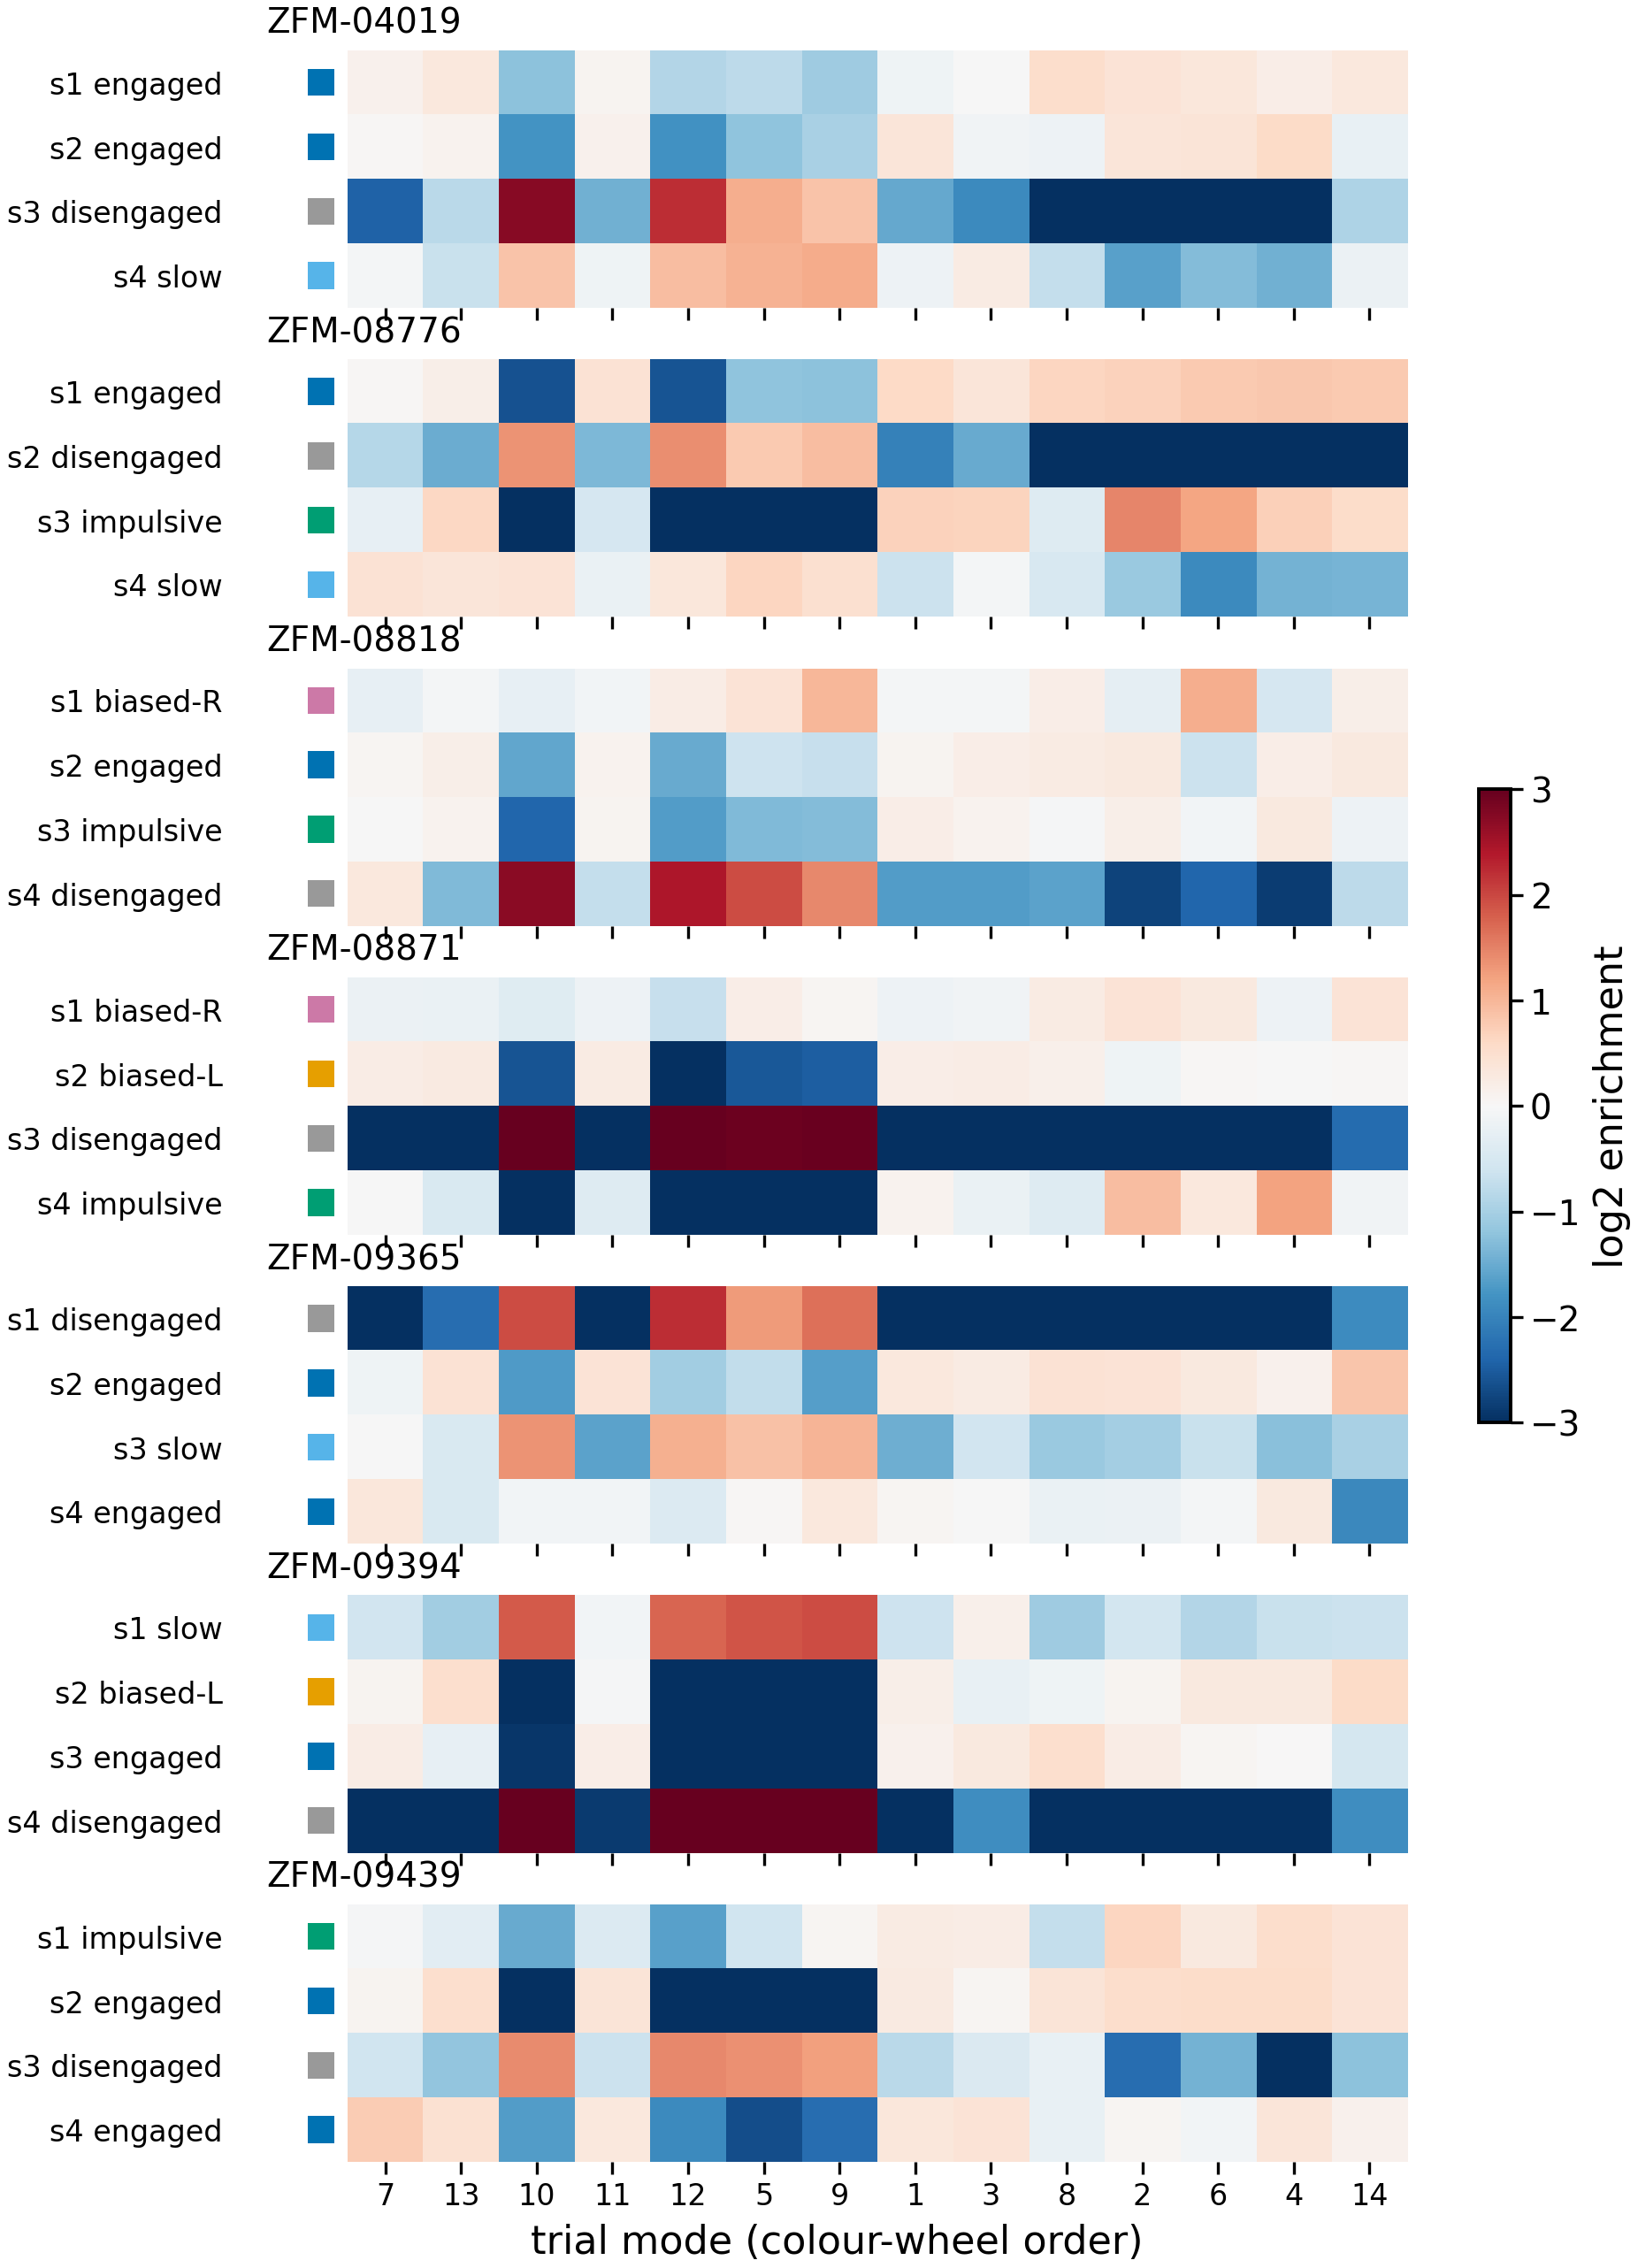

In [3]:
LIM = 3

def enrichment(g, pseudo=1):
    ct = pd.crosstab(g['state'], g['mode']).reindex(columns=MODE_ORDER, fill_value=0)
    exp = ct.sum(1).to_numpy()[:, None] * ct.sum(0).to_numpy()[None] / ct.to_numpy().sum()
    return pd.DataFrame(np.log2((ct + pseudo) / (exp + pseudo)), index=ct.index, columns=ct.columns)

def heat(ax, E, row_labels, row_colors, lim=LIM, annotate=None):
    im = ax.imshow(E.to_numpy(), cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
    ax.set_xticks(range(E.shape[1]), E.columns, fontsize=6)
    ax.set_yticks(range(E.shape[0]), row_labels, fontsize=6)
    ax.scatter(np.full(E.shape[0], -0.85), range(E.shape[0]), marker='s', s=30, c=row_colors, clip_on=False)
    ax.tick_params(axis='y', pad=9, length=0)
    if annotate is not None:
        for (i, jj), v in np.ndenumerate(annotate.to_numpy()):
            ax.text(jj, i, v, ha='center', va='center', fontsize=4.5,
                    color='white' if abs(E.iat[i, jj]) > 0.6 * lim else '0.15')
    for s in ax.spines.values():
        s.set_visible(False)
    return im

ENR = {m: enrichment(j[j['subject'] == m]) for m in MICE}
fig, axes = plt.subplots(len(MICE), 1, figsize=(5.2, 1.05 * len(MICE) + 0.4))
for ax, m in zip(axes, MICE):
    lab = labels[labels['subject'] == m].set_index('state')
    E = ENR[m]
    im = heat(ax, E, lab.loc[E.index, 'tag'], [dh.LABEL_COLORS[l] for l in lab.loc[E.index, 'label']])
    ax.set_title(m, fontsize=7, loc='left')
    ax.set_xticks(range(E.shape[1]), E.columns if m == MICE[-1] else [], fontsize=6)
axes[-1].set_xlabel('trial mode (colour-wheel order)')
fig.colorbar(im, ax=axes, shrink=0.3, label='log2 enrichment')
plt.show()

## The mapping by state kind

Below is the same enrichment averaged over the states that share a name. With two engaged states in a mouse, both count. Each cell shows how many of those states have an enrichment of the same sign as the mean.

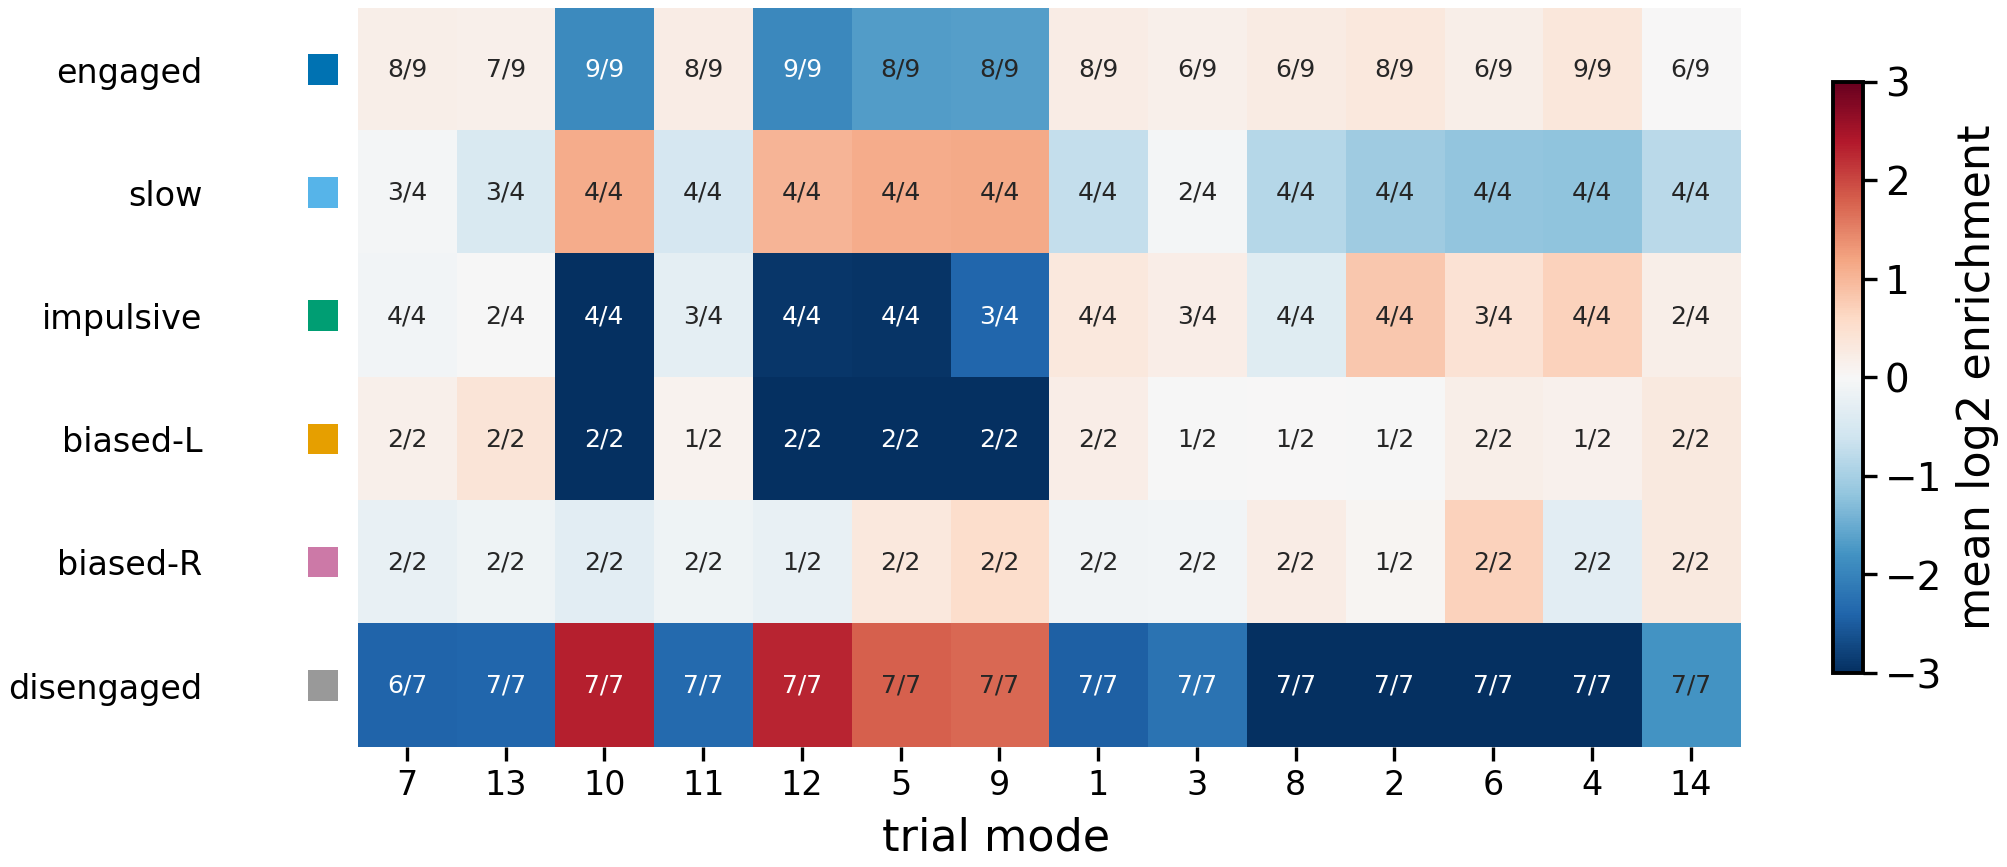

In [4]:
long = pd.concat([ENR[m].stack().rename('enr').reset_index().assign(subject=m) for m in MICE], ignore_index=True)
long = long.merge(labels[['subject', 'state', 'label']], on=['subject', 'state'])
KINDS = [k for k in dh.LABEL_COLORS if k in set(long['label'])]

def by_kind(long):
    mean = long.groupby(['label', 'mode'])['enr'].mean().unstack().reindex(index=KINDS, columns=MODE_ORDER)
    agree = (long.assign(s=np.sign(long['enr']))
             .merge(mean.stack().rename('m').reset_index(), on=['label', 'mode'])
             .assign(a=lambda x: x['s'] == np.sign(x['m']))
             .groupby(['label', 'mode'])['a'].agg(lambda a: f'{a.sum()}/{len(a)}')
             .unstack().reindex(index=KINDS, columns=MODE_ORDER))
    return mean, agree

mean, agree = by_kind(long)
fig, ax = plt.subplots(figsize=(6, 2.4))
im = heat(ax, mean, KINDS, [dh.LABEL_COLORS[k] for k in KINDS], annotate=agree)
ax.set_xlabel('trial mode'); fig.colorbar(im, ax=ax, shrink=0.8, label='mean log2 enrichment')
plt.show()

## How strong is the association, and is it more than chance?

The measure is the mutual information between state and mode per mouse, in bits and as a fraction of H(state). The null circularly shifts each session's state sequence against its mode sequence 200 times. This keeps the autocorrelation of both sequences.

In [5]:
def mi(a, b):
    ct = pd.crosstab(a, b).to_numpy().astype(float); p = ct / ct.sum()
    pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return (p[nz] * np.log2(p[nz] / (pa @ pb)[nz])).sum()

def H(a):
    p = pd.Series(a).value_counts(normalize=True).to_numpy(); return -(p * np.log2(p)).sum()

rng = np.random.default_rng(0)
N_SHIFT = 200
rows = []
for m in MICE:
    g = j[j['subject'] == m].sort_values(['session_idx', 'trial'])
    sessions = [x['state'].to_numpy() for _, x in g.groupby('eid', sort=False)]
    mode_seq = g['mode'].to_numpy()
    raw = mi(g['state'].to_numpy(), mode_seq)
    null = np.array([mi(np.concatenate([np.roll(s, rng.integers(1, len(s))) for s in sessions]), mode_seq)
                     for _ in range(N_SHIFT)])
    rows.append({'subject': m, 'n': len(g), 'MI (bits)': raw, 'null mean': null.mean(),
                 'z': (raw - null.mean()) / null.std(), 'p': (1 + (null >= raw).sum()) / (N_SHIFT + 1),
                 'MI − null, / H(state)': (raw - null.mean()) / H(g['state'])})
strength = pd.DataFrame(rows).set_index('subject')
strength.round(3)

,n,MI (bits),null mean,z,p,"MI − null, / H(state)"
subject,,,,,,
ZFM-04019,12738,0.222,0.013,91.667,0.005,0.121
ZFM-08776,12247,0.366,0.022,65.660,0.005,0.214
ZFM-08818,14902,0.185,0.006,68.837,0.005,0.099
ZFM-08871,27380,0.334,0.007,289.973,0.005,0.220
ZFM-09365,28601,0.185,0.028,45.086,0.005,0.096
ZFM-09394,37422,0.304,0.028,135.772,0.005,0.166
ZFM-09439,32187,0.316,0.009,117.698,0.005,0.166


## What carries the association?

Here the mutual information is computed *conditional* on task variables. Within each stratum, the plug-in MI is debiased by subtracting the value obtained with modes permuted inside the stratum. The table gives what is left as a fraction of the unconditional MI, which is debiased the same way. A value near 1 means the variable explains none of the association; a value near 0 means it explains all of it.

- **RT**: deciles of response − stimOn, within mouse.
- **outcome, contrast, choice**: correct/error, |contrast| as 0 / ≤12.5 / ≥25, and choice side.
- **position**: quintile of trial position in the session.
- **session**: which session.

In [6]:
j['rt_dec'] = j.groupby('subject')['rt'].transform(lambda x: pd.qcut(x, 10, labels=False))
j['rt_ter'] = j.groupby('subject')['rt'].transform(lambda x: pd.qcut(x, 3, labels=False))
j['c_bin'] = pd.cut(j['contrast'], [-1, 0, 12.5, 101], labels=False)
j['pos'] = pd.cut(j['trial_frac'], 5, labels=False)

def cmi(g, strata, col='mode'):
    if strata is None:
        return mi(g['state'], g[col])
    return sum(len(x) / len(g) * mi(x['state'], x[col]) for _, x in g.groupby(strata) if len(x) > 20)

def debiased(g, strata, rng):
    shuffled = g.assign(_m=(rng.permutation(g['mode'].to_numpy()) if strata is None else
                            g.groupby(strata)['mode'].transform(lambda x: rng.permutation(x.to_numpy()))))
    return cmi(g, strata) - cmi(shuffled, strata, '_m')

CONTROLS = {
    'outcome': ['correct'], 'contrast': ['c_bin'], 'choice': ['choice'], 'position': ['pos'],
    'session': ['eid'], 'RT': ['rt_dec'],
    'outcome×contrast×RT(3)': ['correct', 'c_bin', 'rt_ter'],
    'all of the above (RT 3)': ['correct', 'c_bin', 'rt_ter', 'choice', 'pos'],
}
rng = np.random.default_rng(1)
rows = []
for m in MICE:
    g = j[j['subject'] == m]
    base = debiased(g, None, rng)
    rows.append({'subject': m, **{k: debiased(g, v, rng) / base for k, v in CONTROLS.items()}})
cond = pd.DataFrame(rows).set_index('subject')
display(cond.round(2).style.format(precision=2).background_gradient(cmap='Greens', vmin=0, vmax=1))
print('median across mice:'); print(cond.median().round(2).to_dict())

,outcome,contrast,choice,position,session,RT,outcome×contrast×RT(3),all of the above (RT 3)
subject,,,,,,,,
ZFM-04019,1.07,1.50,1.02,0.96,1.03,0.09,0.19,0.19
ZFM-08776,1.01,1.07,0.97,0.58,0.98,0.11,0.13,0.05
ZFM-08818,1.08,1.26,1.00,0.53,1.09,0.25,0.55,0.21
ZFM-08871,0.99,0.97,1.05,0.97,0.98,0.08,0.54,0.41
ZFM-09365,0.97,1.06,1.06,0.55,1.09,0.20,0.29,0.19
ZFM-09394,0.96,0.98,1.07,0.93,0.89,0.08,0.53,0.43
ZFM-09439,0.99,0.99,0.90,0.84,1.04,0.10,0.25,0.17


median across mice:
{'outcome': 0.99, 'contrast': 1.06, 'choice': 1.02, 'position': 0.84, 'session': 1.03, 'RT': 0.1, 'outcome×contrast×RT(3)': 0.29, 'all of the above (RT 3)': 0.19}


## The mapping at matched RT

This version removes RT from the enrichment. For each state, the expected mode counts are built from the state's own RT-decile distribution, using P(mode | RT decile) of the mouse. The log2(observed / expected) values are then averaged by state kind, as above. What remains is which modes a state uses *beyond* what its RTs predict.

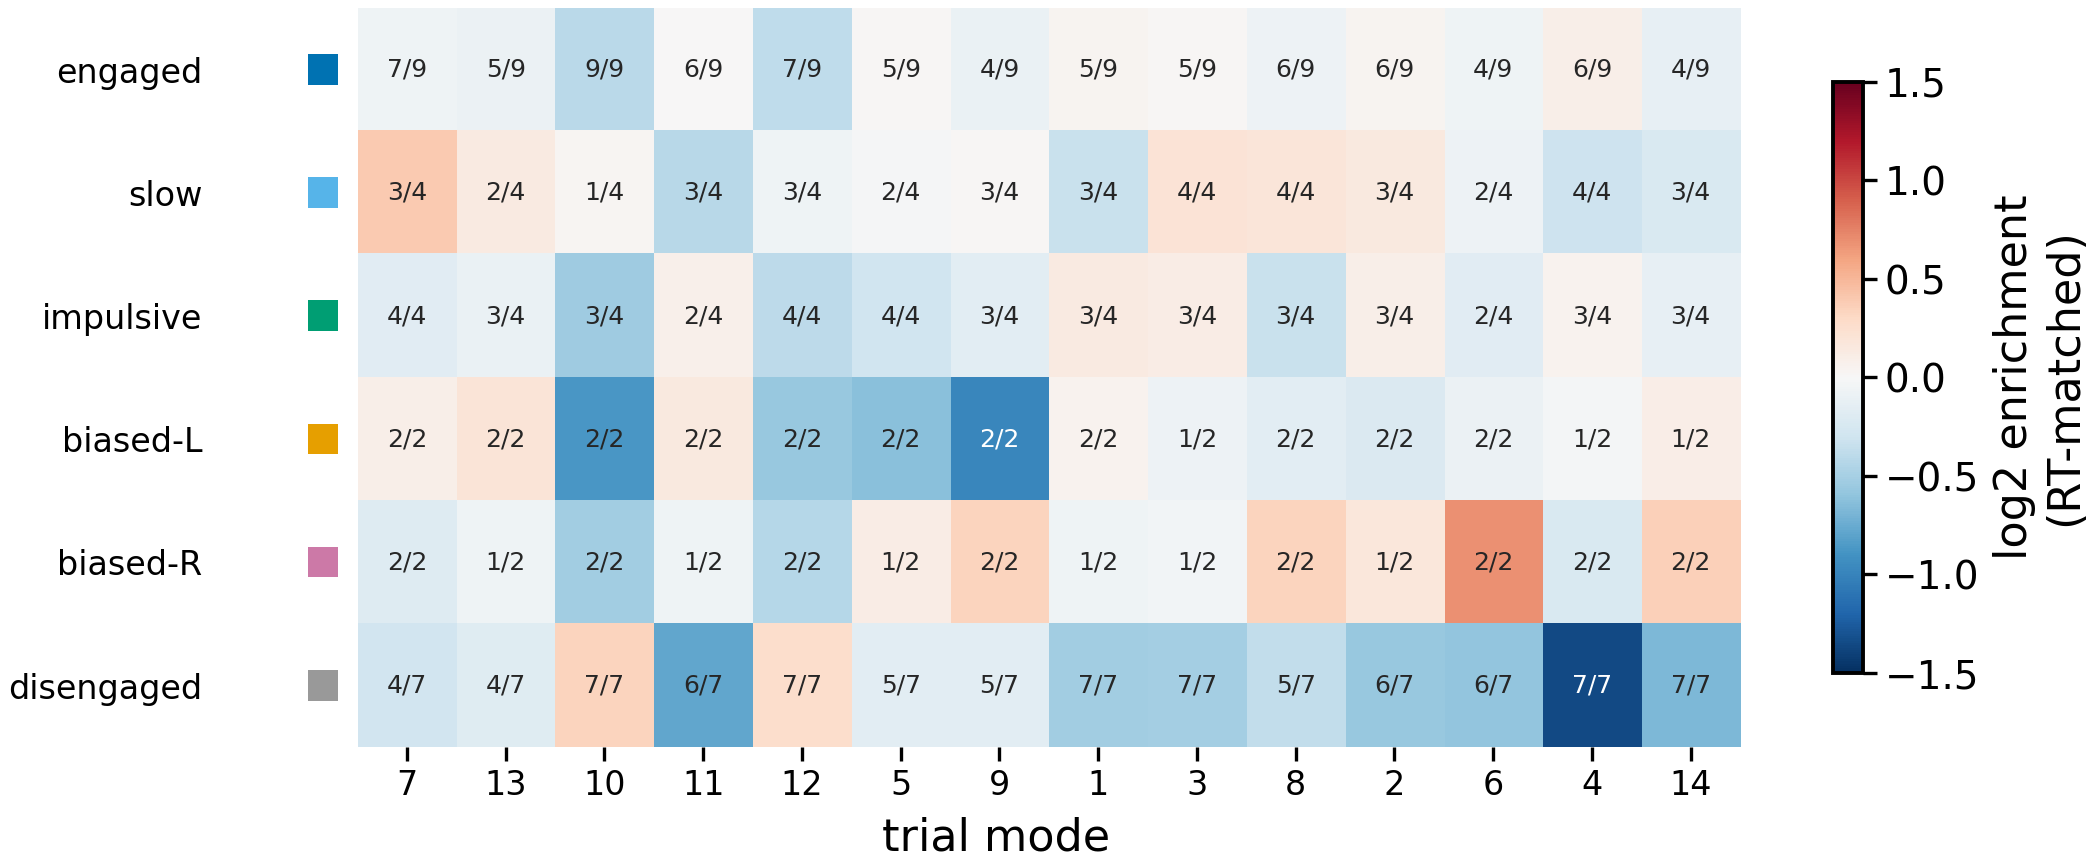

In [7]:
rows = []
for m in MICE:
    g = j[j['subject'] == m]
    pm_rt = pd.crosstab(g['rt_dec'], g['mode'], normalize='index').reindex(columns=MODE_ORDER, fill_value=0)
    for st, x in g.groupby('state'):
        n_rt = x['rt_dec'].value_counts().reindex(pm_rt.index, fill_value=0).to_numpy()
        exp = n_rt @ pm_rt.to_numpy()
        obs = x['mode'].value_counts().reindex(MODE_ORDER, fill_value=0).to_numpy()
        rows.append(pd.DataFrame({'subject': m, 'state': st, 'mode': MODE_ORDER, 'enr': np.log2((obs + 1) / (exp + 1))}))
long_rt = pd.concat(rows, ignore_index=True).merge(labels[['subject', 'state', 'label']], on=['subject', 'state'])
mean_rt, agree_rt = by_kind(long_rt)
fig, ax = plt.subplots(figsize=(6, 2.4))
im = heat(ax, mean_rt, KINDS, [dh.LABEL_COLORS[k] for k in KINDS], lim=1.5, annotate=agree_rt)
ax.set_xlabel('trial mode'); fig.colorbar(im, ax=ax, shrink=0.8, label='log2 enrichment\n(RT-matched)')
plt.show()

## Which epochs carry the state?

A mode summarises all four epochs at once. Here the DDM state is decoded from each epoch's syllables separately, using the same factored one-hot encoding the modes are built from. The decoder is a multinomial logistic regression (C = 0.1, balanced classes), cross-validated with 5 folds grouped by session, and scored by balanced accuracy. Chance is about 0.25.

- **task**: one-hots of RT decile, outcome, |contrast| bin and choice.
- **mode**: the trial mode one-hot.
- **epoch + task**: what that epoch adds on top of the task variables. The Pre-quiescence and Quiescence epochs come before the stimulus, so whatever they add cannot come from the trial's own decision.

Results are cached in `CACHE`. Set `RECOMPUTE = True` to refit; it takes about 10 minutes.

features,task,mode,Pre-quiescence,Quiescence,Choice,ITI,all epochs,mode + task,Pre-quiescence + task,Quiescence + task,Choice + task,ITI + task,all epochs + task
subject,,,,,,,,,,,,,
ZFM-04019,0.586,0.451,0.372,0.450,0.540,0.346,0.551,0.600,0.602,0.603,0.604,0.589,0.601
ZFM-08776,0.718,0.471,0.377,0.567,0.650,0.384,0.653,0.725,0.727,0.719,0.733,0.730,0.734
ZFM-08818,0.684,0.431,0.383,0.478,0.534,0.411,0.565,0.686,0.690,0.687,0.686,0.691,0.690
ZFM-08871,0.748,0.530,0.372,0.516,0.600,0.352,0.622,0.759,0.748,0.751,0.764,0.751,0.765
ZFM-09365,0.586,0.462,0.361,0.418,0.534,0.403,0.575,0.589,0.590,0.590,0.598,0.597,0.620
ZFM-09394,0.680,0.504,0.342,0.498,0.618,0.383,0.641,0.686,0.681,0.693,0.713,0.682,0.725
ZFM-09439,0.614,0.417,0.339,0.461,0.526,0.385,0.566,0.625,0.628,0.625,0.627,0.636,0.650


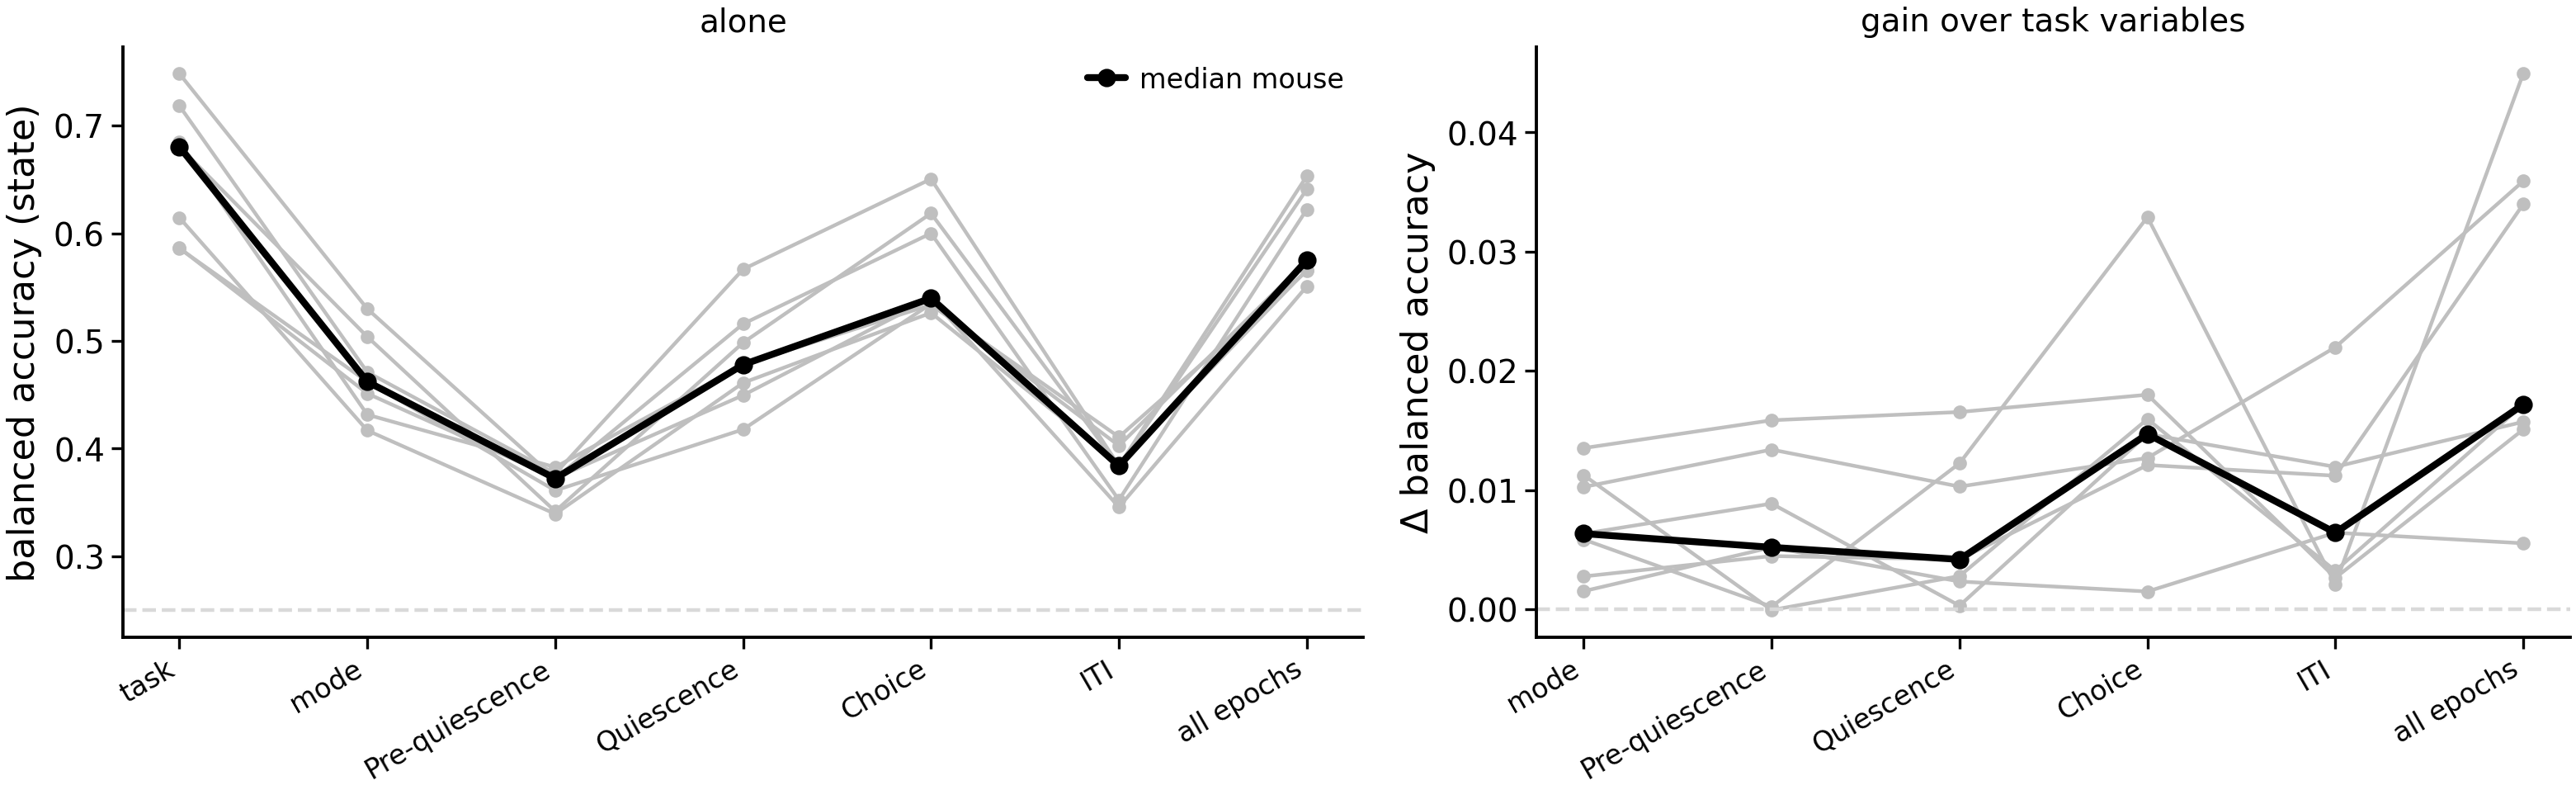

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score

RECOMPUTE = False
DEC_FILE = CACHE / f'ddm_k{K}_state_decoding_{RUN}.pqt'

def onehots(g, cols):
    return np.hstack([pd.get_dummies(g[c].astype(str)).to_numpy(float) for c in cols])

if DEC_FILE.exists() and not RECOMPUTE:
    dec = pd.read_parquet(DEC_FILE)
else:
    rows = []
    for m in MICE:
        g = j[j['subject'] == m].reset_index(drop=True)
        y, groups = g['state'].to_numpy(), g['eid'].to_numpy()
        task_X = onehots(g, ['rt_dec', 'correct', 'c_bin', 'choice'])
        feats = {'task': task_X, 'mode': onehots(g, ['mode'])}
        for ep in tm.EPOCHS:
            feats[ep] = tm.encode(np.vstack(g[ep].to_numpy()).astype(float))
        feats['all epochs'] = np.hstack([feats[ep] for ep in tm.EPOCHS])
        for name in ['mode', *tm.EPOCHS, 'all epochs']:
            feats[f'{name} + task'] = np.hstack([feats[name], task_X])
        for name, X in feats.items():
            p = cross_val_predict(LogisticRegression(max_iter=500, C=0.1, class_weight='balanced'),
                                  X, y, groups=groups, cv=GroupKFold(5), n_jobs=5)
            rows.append({'subject': m, 'features': name, 'balanced_accuracy': balanced_accuracy_score(y, p)})
    dec = pd.DataFrame(rows)
    dec.to_parquet(DEC_FILE)

tab = dec.pivot(index='subject', columns='features', values='balanced_accuracy')
alone = ['task', 'mode', *tm.EPOCHS, 'all epochs']
plus = [f'{n} + task' for n in ['mode', *tm.EPOCHS, 'all epochs']]
display(tab[alone + plus].round(3))
gain = tab[plus].sub(tab['task'], axis=0)
gain.columns = [c.removesuffix(' + task') for c in gain.columns]

fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), width_ratios=[1.2, 1])
for ax, T, title in [(axes[0], tab[alone], 'alone'), (axes[1], gain, 'gain over task variables')]:
    x = np.arange(T.shape[1])
    for m in T.index:
        ax.plot(x, T.loc[m], color='0.75', lw=0.8, marker='o', ms=2)
    ax.plot(x, T.median(), color='k', lw=1.5, marker='o', ms=3, label='median mouse')
    ax.set_xticks(x, T.columns, rotation=30, ha='right', fontsize=6); ax.set_title(title, fontsize=7)
axes[0].axhline(0.25, color='0.85', ls='--', lw=0.8); axes[0].set_ylabel('balanced accuracy (state)')
axes[1].axhline(0, color='0.85', ls='--', lw=0.8); axes[1].set_ylabel('Δ balanced accuracy')
axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

## Summary

**The mapping is strong, consistent across mice, and mostly about speed.**

- **Strength.** Mode carries 10–22% of the state's entropy in every mouse. This is far above a circular-shift null that keeps the autocorrelation (z = 45–290).
- **The main axis is slow modes vs fast modes.** Four modes, **5, 9, 10 and 12**, have median RTs of about 2.5–2.8 s and a still, non-whisking Choice epoch. They are the modes of the **disengaged** states, which over-use them about 3–7× (7/7 mice), and they are milder in the **slow** states (4/4). **Engaged, impulsive and biased-L** states avoid them. Within the fast modes, **impulsive** states lean toward modes 2 and 4, which have the most vigorous Choice-epoch movement. **Biased-R** states lean toward mode 6.
- **RT carries most of it.** Holding RT fixed (deciles) leaves a median of only 10% of the association. Outcome, contrast, choice side and session leave it untouched, and position in the session explains a little (median 0.84). Holding RT, outcome, contrast, choice and position fixed together still leaves about 19%; RT terciles are a coarser control than deciles. This is expected: the DDM states are defined largely by their RT distributions, and the modes see RT through how still the Choice epoch is.
- **What survives at matched RT is pre-trial stillness.** At the same RT, disengaged states still over-use **modes 10 and 12** (7/7 mice), the modes with a frozen paw before the trial (Pre-quiescence vigor ≈ 0.0–0.1). They avoid **mode 4** in all 7 mice. Engaged states avoid 10 (9/9). Biased-L states avoid 9 and 10, and biased-R states over-use 6.
- **The epochs.** Pre-stimulus behaviour decodes the state well above chance: Quiescence alone gives a balanced accuracy of 0.42–0.57 against a chance level of 0.25. But it adds only about 0.00–0.02 once the task variables (RT, outcome, contrast, choice) are known. All four epochs together add 0.01–0.05. The behaviour is therefore largely *redundant* with what the DDM already reads from choices and RTs, with a small extra part. The most consistent extra part is the pre-trial stillness of disengaged trials.

**Caveats**
- These are 7 mice with per-mouse fits, and the state names are the provisional ones from step 2.
- ZFM-08776 (the legacy fit) has a mode on only 54% of its trials, against 80–96% for the other mice. Its syllables fall on the KDE background unusually often, so its contingency rests on a biased half of its trials.
- The DDM state is inferred from the trial's own choice and RT, so any RT-linked behaviour will map onto it. This is why the RT-matched view and the pre-stimulus decoding are the informative ones.